# LUR Results

Post-processing and visualization of land use regression results.


In [ ]:
import json
from pathlib import Path

import contextily as cx
import geopandas as gpd
import libpysal
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xarray as xr
from focalpy.model_selection import _as_coordinate_array
from libpysal.weights import KNN
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from skops import io as sio

from zurich_uhi_lur import regr_utils

sns.set_theme(style="ticks")

In [ ]:
# input data paths
stations_gdf_filepath = "../data/processed/stations.gpkg"
station_features_filepath = "../data/processed/stations-features.csv"
ts_df_filepath = "../data/processed/ts-df.csv"
grid_gdf_filepath = "../data/processed/regular-grid.gpkg"
grid_features_filepath = "../data/processed/grid-features.csv"

# LUR results
models_dir = "../models"
dst_results_filepath = "../data/processed/lur-results.csv"
dst_importance_filepath = "../data/processed/lur-importance.csv"
obs_pred_data_filepath = "../data/processed/lur-obs-pred.csv"
dst_baseline_moran_filepath = "../data/processed/baseline-moran.json"

# output figures
dst_scores_filepath = "../reports/figures/lur-scores.pdf"
dst_rsa_filepath = "../reports/figures/lur-rsa.pdf"
dst_importance_fig_prefix = "../reports/figures/lur-importance"
dst_maps_filepath = "../reports/figures/lur-maps.png"
dst_pca_filepath = "../reports/figures/lur-pca.pdf"
dst_pca_loadings_filepath = "../reports/figures/lur-pca-loadings.pdf"
dst_obs_pred_filepath = "../reports/figures/lur-obs-pred.pdf"

# experiment settings (must match lur-fit)
target_hour = 21
fracs = [0, 0.33, 0.66, 1]
seed = 0
n_reps = 5

# trusted types for skops
trusted = [
    "interpret.glassbox._ebm._ebm.ExplainableBoostingRegressor",
    "zurich_uhi_lur.regr_utils.SpearmanSFSSelector",
    "flaml.automl.data.DataTransformer",
    "flaml.automl.model.RandomForestEstimator",
    "flaml.automl.task.generic_task.GenericTask",
    "flaml.default.estimator.RandomForestRegressor",
    "flaml.default.suggest.AutoMLTransformer",
    "sklearn.ensemble._forest.RandomForestRegressor",
]

# how to get model keys programmatically?
MODEL_KEYS = ["OLS", "GAM", "RF"]

## Load results


In [ ]:
results_df = pd.read_csv(dst_results_filepath)
importance_df = pd.read_csv(dst_importance_filepath)
obs_pred_df = pd.read_csv(obs_pred_data_filepath)

with open(dst_baseline_moran_filepath) as f:
    baseline_moran = json.load(f)

# Load all pipelines
frac_pipelines = {}
for frac in fracs:
    frac_pipelines[frac] = {}
    for model_key in MODEL_KEYS:
        pipe_path = Path(models_dir) / f"pipeline-frac{frac}-{model_key}.skops"
        if pipe_path.exists():
            frac_pipelines[frac][model_key] = sio.load(pipe_path, trusted=trusted)

final_pipelines = frac_pipelines[fracs[-1]]

print(f"Loaded {len(results_df)} result rows, {len(importance_df)} importance rows")
print(f"Pipelines: { {f: list(m.keys()) for f, m in frac_pipelines.items()} }")

Loaded 60 result rows, 510 importance rows
Pipelines: {0: ['OLS', 'GAM', 'RF'], 0.33: ['OLS', 'GAM', 'RF'], 0.66: ['OLS', 'GAM', 'RF'], 1: ['OLS', 'GAM', 'RF']}


In [ ]:
station_features_gdf = regr_utils.get_site_features_gdf(
    station_features_filepath,
    stations_gdf_filepath,
)
aws_gdf = station_features_gdf[station_features_gdf["source"] == "AWS"]
lcd_gdf = station_features_gdf[station_features_gdf["source"] == "LCD"]

grid_features_gdf = regr_utils.get_site_features_gdf(
    grid_features_filepath,
    grid_gdf_filepath,
)

## Postprocessing

### Model performance and residual spatial autocorrelation

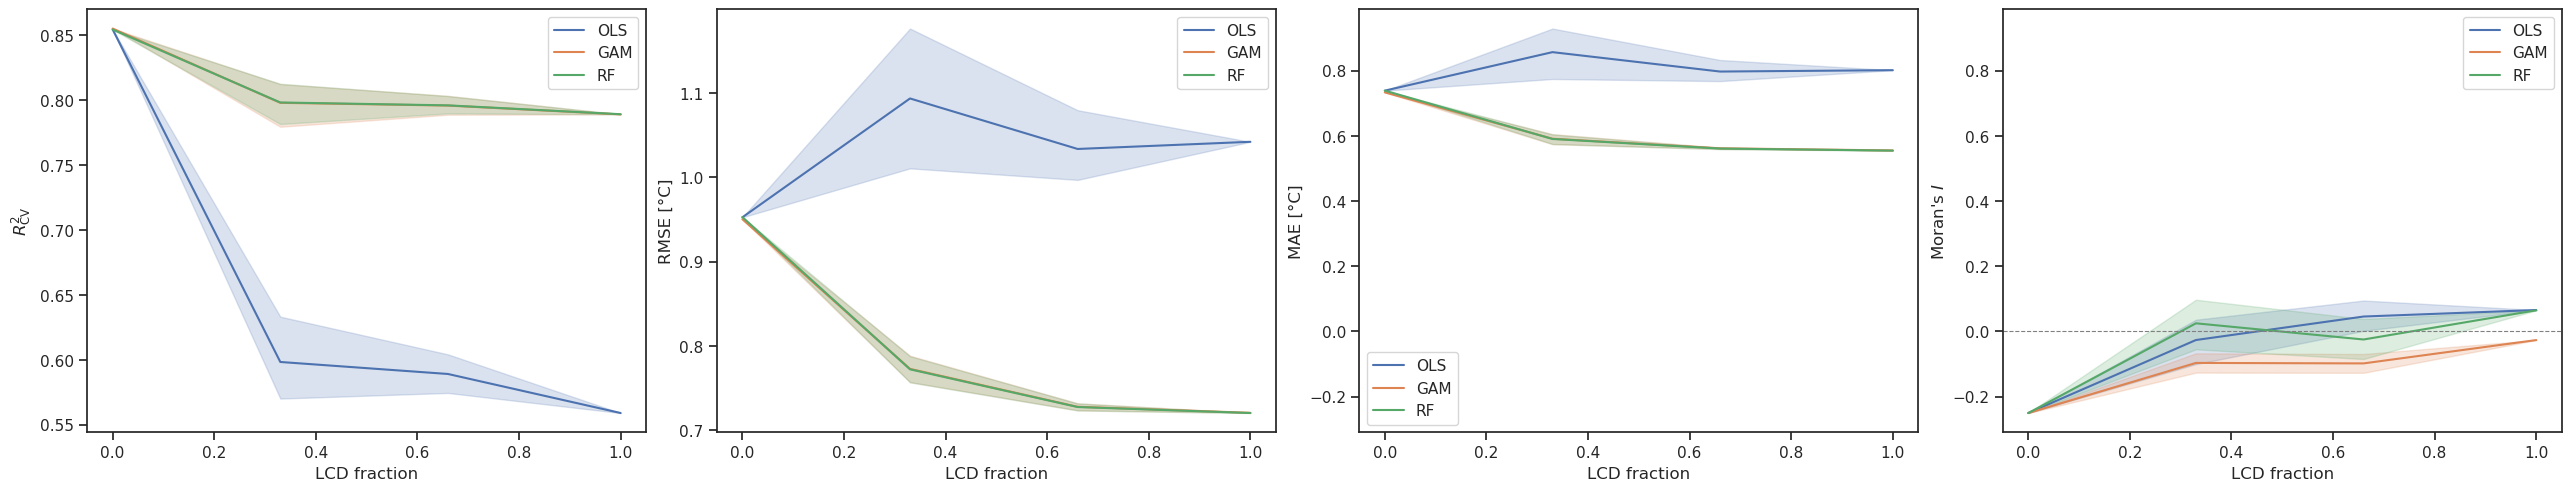

In [ ]:
figwidth, figheight = plt.rcParams["figure.figsize"]

# Per-rep RMSE and MAE from obs_pred_df so sns.lineplot can show CI across reps
error_df = (
    obs_pred_df.assign(
        sq_error=lambda d: (d["pred"] - d["obs"]) ** 2,
        abs_error=lambda d: (d["pred"] - d["obs"]).abs(),
    )
    .groupby(["model", "frac", "rep"])
    .agg(rmse=("sq_error", lambda x: np.sqrt(x.mean())), mae=("abs_error", "mean"))
    .reset_index()
)
plot_df = results_df.merge(error_df, on=["model", "frac", "rep"])

metrics = [
    ("r2_cv", r"$R^2_{\mathrm{CV}}$"),
    ("rmse", "RMSE [\u00b0C]"),
    ("mae", "MAE [\u00b0C]"),
    ("moran_I", r"Moran's $I$"),
]

fig, axes = plt.subplots(
    1, 4, figsize=(4 * figwidth, figheight), constrained_layout=True, sharex=True
)
# RMSE and MAE share y: same unit, comparable magnitude
axes[3].sharey(axes[2])

for ax, (metric, ylabel) in zip(axes, metrics):
    data = plot_df if metric in ("rmse", "mae") else results_df
    sns.lineplot(
        data=data,
        x="frac",
        y=metric,
        hue="model",
        ax=ax,
    )
    if metric == "moran_I":
        ax.axhline(0, color="0.5", linestyle="--", linewidth=0.8)
    ax.set_xlabel("LCD fraction")
    ax.set_ylabel(ylabel)
    ax.legend(title="")

fig.savefig(dst_scores_filepath, bbox_inches="tight")

### Spatial station coverage per LCD fraction

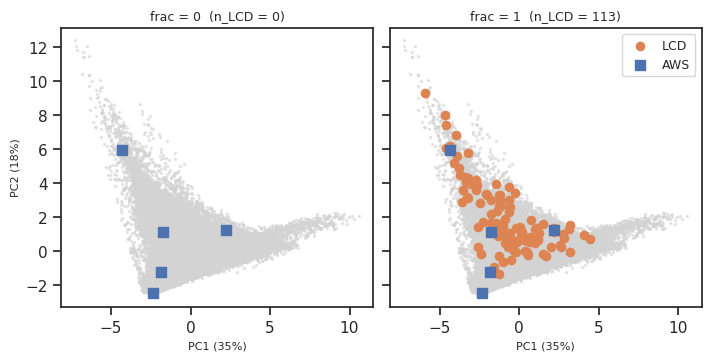

In [ ]:
X_grid = grid_features_gdf.drop(columns=["geometry", "source"], errors="ignore")

sample_per_frac = {
    fracs[0]: aws_gdf.drop(columns="source"),
    fracs[-1]: pd.concat([aws_gdf, lcd_gdf]).drop(columns="source"),
}
plot_fracs = [fracs[0], fracs[-1]]

# Fit PCA on the grid — defines the reference variance landscape
scaler_pca = StandardScaler()
X_grid_scaled = scaler_pca.fit_transform(X_grid.values)
pca = PCA(n_components=2)
grid_pcs = pca.fit_transform(X_grid_scaled)
var_exp = pca.explained_variance_ratio_

fig, axes = plt.subplots(
    1,
    len(plot_fracs),
    figsize=(3.5 * len(plot_fracs), 3.5),
    constrained_layout=True,
    sharex=True,
    sharey=True,
)

for ax, frac in zip(axes, plot_fracs):
    ax.scatter(
        grid_pcs[:, 0],
        grid_pcs[:, 1],
        c="lightgrey",
        s=2,
        alpha=0.5,
        zorder=0,
        rasterized=True,
    )

    sample_gdf = sample_per_frac[frac]
    X_sample = sample_gdf.drop(columns="geometry").reindex(columns=X_grid.columns)
    sample_pcs = pca.transform(scaler_pca.transform(X_sample.values))

    aws_mask = sample_gdf.index.isin(aws_gdf.index)
    ax.scatter(
        sample_pcs[~aws_mask, 0],
        sample_pcs[~aws_mask, 1],
        c="C1",
        s=35,
        zorder=2,
        label="LCD",
    )
    ax.scatter(
        sample_pcs[aws_mask, 0],
        sample_pcs[aws_mask, 1],
        c="C0",
        marker="s",
        s=45,
        zorder=3,
        label="AWS",
    )

    n_lcd = (~aws_mask).sum()
    ax.set_title(f"frac = {frac}  (n_LCD = {n_lcd})", fontsize=9)
    ax.set_xlabel(f"PC1 ({var_exp[0]:.0%})", fontsize=8)

axes[0].set_ylabel(f"PC2 ({var_exp[1]:.0%})", fontsize=8)

axes[-1].legend(loc="best", fontsize=9)
fig.savefig(dst_pca_filepath, bbox_inches="tight")

#### PCA loadings

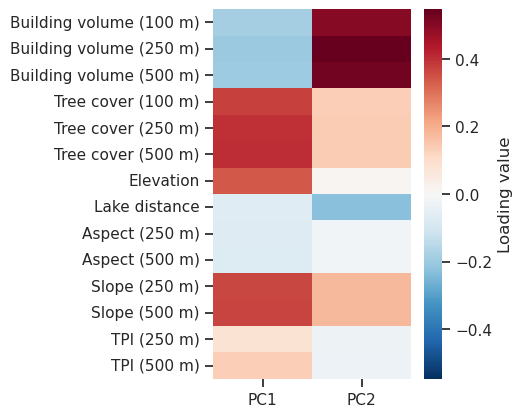

In [ ]:
figwidth, figheight = plt.rcParams["figure.figsize"]

pca_feature_labels = {
    "building_volume_sum_100": "Building volume (100 m)",
    "building_volume_sum_250": "Building volume (250 m)",
    "building_volume_sum_500": "Building volume (500 m)",
    "tree_sum_100": "Tree cover (100 m)",
    "tree_sum_250": "Tree cover (250 m)",
    "tree_sum_500": "Tree cover (500 m)",
    "elevation_0": "Elevation",
    "lake_distance_0": "Lake distance",
    "aspect_mean_250": "Aspect (250 m)",
    "aspect_mean_500": "Aspect (500 m)",
    "slope_mean_250": "Slope (250 m)",
    "slope_mean_500": "Slope (500 m)",
    "topographic_position_index_mean_250": "TPI (250 m)",
    "topographic_position_index_mean_500": "TPI (500 m)",
}

loading_df = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i + 1}" for i in range(pca.n_components_)],
    index=X_grid.columns,
).rename(index=pca_feature_labels)
max_abs = max(abs(loading_df.min().min()), loading_df.max().max())

fig, ax = plt.subplots(figsize=(0.5 * figwidth, figheight))
sns.heatmap(
    loading_df,
    cmap="RdBu_r",
    vmin=-max_abs,
    vmax=max_abs,
    cbar_kws={"label": "Loading value"},
    ax=ax,
)
fig.savefig(dst_pca_loadings_filepath, bbox_inches="tight")

### Observed vs predicted

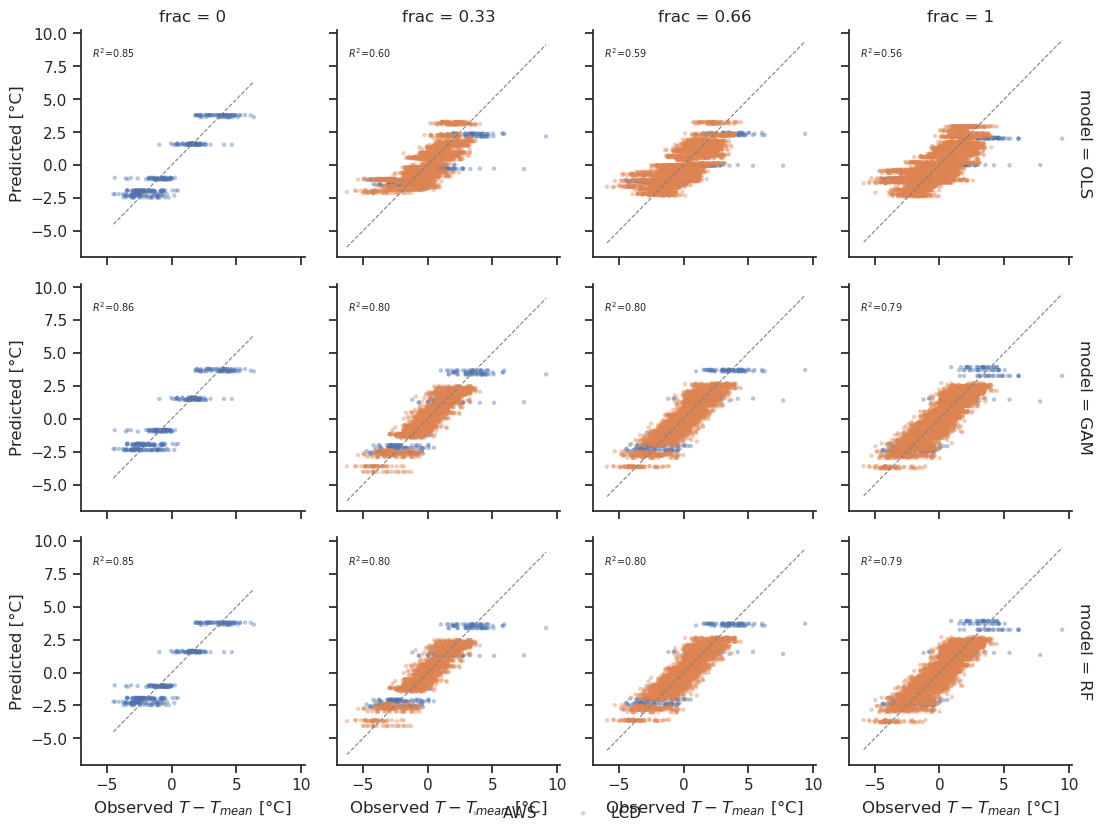

In [ ]:
# Show rep=0 for each frac: one representative sample, avoids overplotting multiple reps
plot_df = obs_pred_df[obs_pred_df["rep"] == 0].copy()

g = sns.FacetGrid(
    plot_df,
    row="model",
    col="frac",
    col_order=fracs,
    row_order=MODEL_KEYS,
    hue="source",
    palette={"AWS": "C0", "LCD": "C1"},
    height=2.8,
    aspect=1,
    sharex=True,
    sharey=True,
    margin_titles=True,
)
g.map(plt.scatter, "obs", "pred", alpha=0.4, s=10, edgecolors="none")

# identity line and per-panel R²_cv annotation
for (row_val, col_val), ax in g.axes_dict.items():
    sub = plot_df.query("model == @row_val and frac == @col_val")
    lo = min(sub["obs"].min(), sub["pred"].min())
    hi = max(sub["obs"].max(), sub["pred"].max())
    ax.plot([lo, hi], [lo, hi], color="gray", linewidth=0.8, linestyle="--")
    r2_val = results_df.query("model == @row_val and frac == @col_val")["r2_cv"].mean()
    ax.text(
        0.05,
        0.93,
        f"$R^2$={r2_val:.2f}",
        transform=ax.transAxes,
        fontsize=7,
        va="top",
    )

g.set_axis_labels("Observed $T - T_{mean}$ [°C]", "Predicted [°C]")
g.add_legend(title="")
sns.move_legend(g, "lower center", ncol=2)
g.figure.savefig(dst_obs_pred_filepath, bbox_inches="tight")

### Moran scatterplots (OOF residuals)


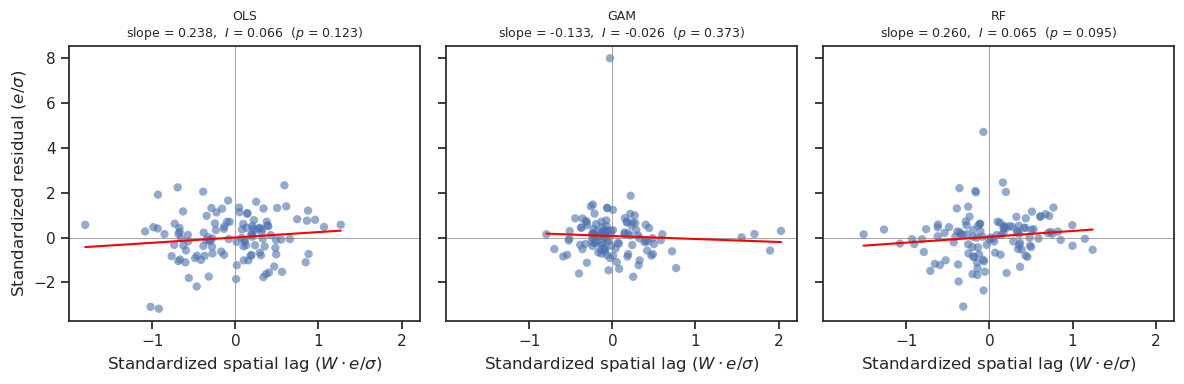

In [ ]:
# Use saved OOF residuals (rep=0, frac=1) so slopes and annotated I come from
# the same pipeline run. Station 534 was excluded from training in lur-fit and
# is therefore absent from obs_pred_df; it is also excluded here from the KNN weights.
station_gdf_moran = pd.concat([aws_gdf, lcd_gdf]).drop(columns="source")
station_gdf_moran = station_gdf_moran[station_gdf_moran.index != "534"]
station_gser_moran = station_gdf_moran["geometry"]

coords = _as_coordinate_array(station_gser_moran)
w_moran = KNN(coords, k=4)
w_moran.transform = "r"
station_ids = station_gser_moran.index  # order matches coords / spatial weights

moran_frac1 = (
    results_df[np.isclose(results_df["frac"], 1)]
    .groupby("model")[["moran_I", "moran_p_sim"]]
    .mean()
)


def _fmt_p(p):
    return "< 0.001" if p < 0.001 else f"= {p:.3f}"


fig, axes = plt.subplots(
    1, len(MODEL_KEYS), figsize=(12, 4), squeeze=False, sharey=True, sharex=True
)

for col, model_key in enumerate(MODEL_KEYS):
    ax = axes[0, col]

    op = obs_pred_df.query("model == @model_key and frac == 1 and rep == 0").copy()
    op["resid"] = op["obs"] - op["pred"]
    site_resid = op.groupby("station_id")["resid"].mean().reindex(station_ids).values
    # Standardise so all panels share the same scale and slope == Moran's I
    site_resid = site_resid / site_resid.std()
    w_lag = libpysal.weights.lag_spatial(w_moran, site_resid)

    ax.axhline(0, color="gray", linewidth=0.5)
    ax.axvline(0, color="gray", linewidth=0.5)
    ax.scatter(w_lag, site_resid, alpha=0.6, edgecolors="none")

    z = np.polyfit(w_lag, site_resid, 1)
    p_poly = np.poly1d(z)
    xs = np.linspace(w_lag.min(), w_lag.max(), 100)
    ax.plot(xs, p_poly(xs), color="red", linewidth=1.5)

    I_val = moran_frac1.loc[model_key, "moran_I"]
    p_val = moran_frac1.loc[model_key, "moran_p_sim"]
    ax.set_title(
        f"{model_key}\nslope = {z[0]:.3f},  $I$ = {I_val:.3f}  ($p$ {_fmt_p(p_val)})",
        fontsize=9,
    )
    ax.set_xlabel("Standardized spatial lag ($W \\cdot e / \\sigma$)")
    if col == 0:
        ax.set_ylabel("Standardized residual ($e / \\sigma$)")

fig.tight_layout()
fig.savefig(dst_rsa_filepath, bbox_inches="tight")

### Feature importances

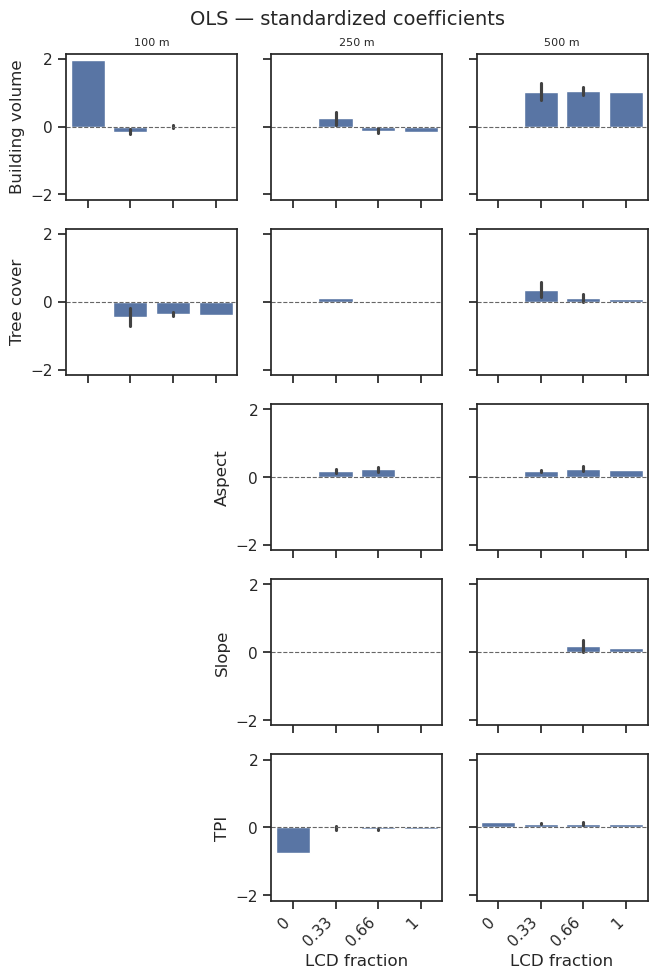

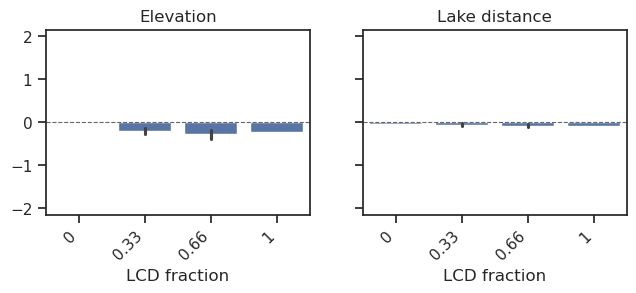

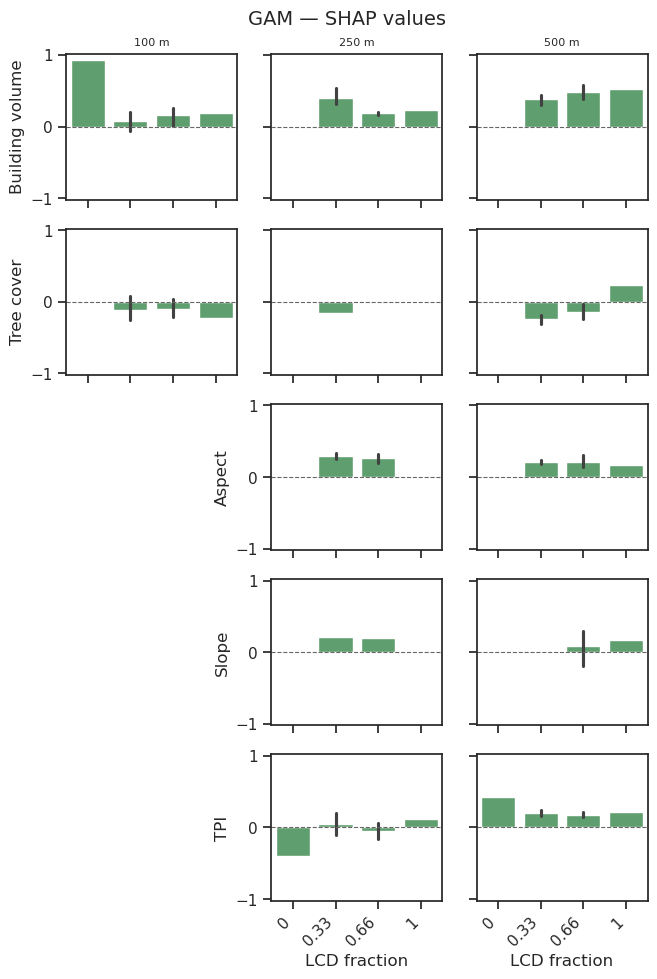

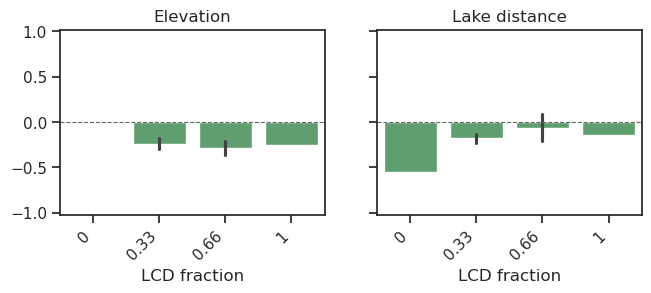

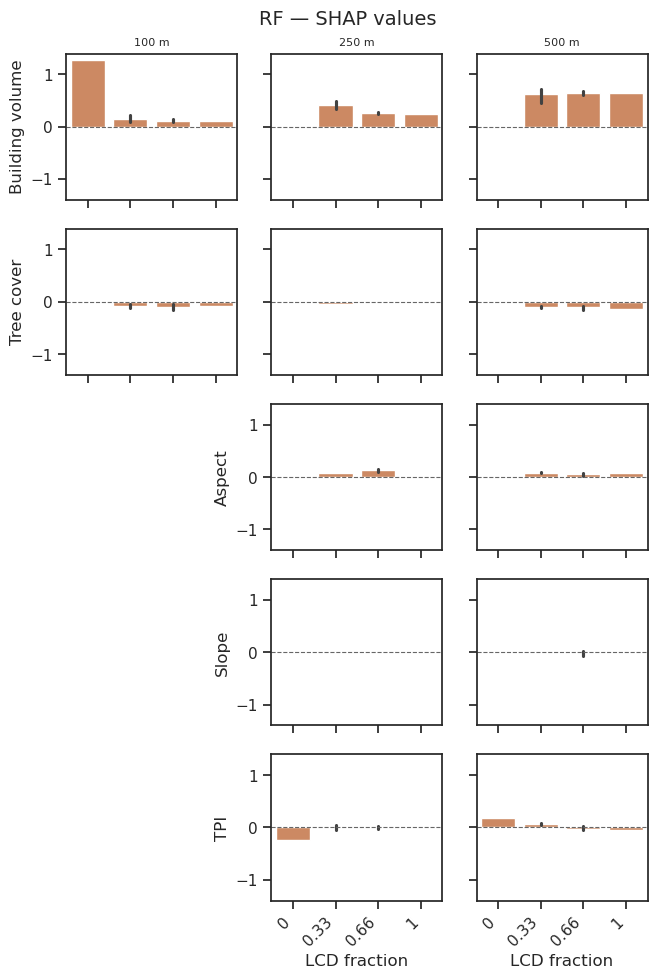

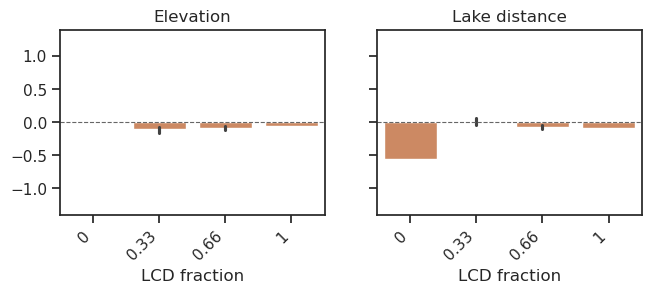

In [ ]:
SCALE_TO_COL = {100: 0, 250: 1, 500: 2}
multi_scale_groups = [
    (
        "Building volume",
        [
            "building_volume_sum_100",
            "building_volume_sum_250",
            "building_volume_sum_500",
        ],
    ),
    ("Tree cover", ["tree_sum_100", "tree_sum_250", "tree_sum_500"]),
    ("Aspect", ["aspect_mean_250", "aspect_mean_500"]),
    ("Slope", ["slope_mean_250", "slope_mean_500"]),
    (
        "TPI",
        ["topographic_position_index_mean_250", "topographic_position_index_mean_500"],
    ),
]
single_scale_groups = [
    ("Elevation", ["elevation_0"]),
    ("Lake distance", ["lake_distance_0"]),
]
frac_order = list(fracs)
MULTI_SCALE_FIGSIZE = (7.5, 11.0)
SINGLE_SCALE_FIGSIZE = (7.5, 2.4)


def _compute_model_ylim(model_name, padding=0.1):
    """Symmetric ylim around 0 so positive/negative importances are equally visible."""
    data = importance_df.query("model == @model_name")["value"]
    max_abs = max(abs(data.min()), abs(data.max()))
    val = max_abs * (1 + padding)
    return (-val, val)


def _barplot_feature(ax, plot_df, feature, color):
    sns.barplot(
        data=plot_df.query("feature == @feature"),
        x="frac",
        y="value",
        order=frac_order,
        estimator="mean",
        errorbar=("ci", 95),
        color=color,
        ax=ax,
    )
    ax.axhline(0, color="0.4", linestyle="--", linewidth=0.8)


def _plot_multi_scale_importance(model_name, color, title, ylim):
    """Multi-scale figure: columns aligned by buffer distance (100/250/500 m).

    Features without a 100 m scale (Aspect, Slope, TPI) are pushed right so
    250 m always falls in col 1 and 500 m in col 2. The feature name is the
    ylabel on the leftmost visible column of each row. All axes share the same
    y range (symmetric around 0) so features can be compared directly.
    """
    plot_df = importance_df.query("model == @model_name").copy()
    n_rows = len(multi_scale_groups)
    n_cols = len(SCALE_TO_COL)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=MULTI_SCALE_FIGSIZE,
        squeeze=False,
        sharex=True,
    )
    fig.suptitle(title, fontsize=14, y=0.92)

    for row_idx, (group_label, group_features) in enumerate(multi_scale_groups):
        is_last_row = row_idx == n_rows - 1
        feat_by_scale = {int(f.rsplit("_", 1)[-1]): f for f in group_features}
        first_col = SCALE_TO_COL[min(feat_by_scale)]

        for scale, col_idx in SCALE_TO_COL.items():
            ax = axes[row_idx, col_idx]
            if scale not in feat_by_scale:
                ax.set_visible(False)
                continue

            _barplot_feature(ax, plot_df, feat_by_scale[scale], color)
            ax.set_ylim(ylim)

            ax.set_title(f"{scale} m" if row_idx == 0 else "", fontsize=8)

            if col_idx == first_col:
                ax.set_ylabel(group_label, fontsize=12)
            else:
                ax.set_ylabel("")
                ax.tick_params(labelleft=False)

            if is_last_row:
                ax.set_xlabel("LCD fraction")
                ax.set_xticks(range(len(frac_order)))
                ax.set_xticklabels(
                    [f"{f:g}" for f in frac_order], rotation=45, ha="right"
                )
            else:
                ax.set_xlabel("")

    return fig


def _plot_single_scale_importance(model_name, color, title, ylim):
    """Single-scale figure: elevation and lake distance in one row, same ylim."""
    plot_df = importance_df.query("model == @model_name").copy()
    n_groups = len(single_scale_groups)

    fig, axes = plt.subplots(
        1,
        n_groups,
        figsize=SINGLE_SCALE_FIGSIZE,
        squeeze=False,
        sharex=True,
    )
    # no suptitle because they are stacked below in the manuscript
    # fig.suptitle(title, fontsize=11, y=1.1)

    for col_idx, (group_label, group_features) in enumerate(single_scale_groups):
        ax = axes[0, col_idx]
        _barplot_feature(ax, plot_df, group_features[0], color)
        ax.set_ylim(ylim)
        ax.set_title(group_label, fontsize=12)
        ax.set_xlabel("LCD fraction")
        ax.set_xticks(range(len(frac_order)))
        ax.set_xticklabels([f"{f:g}" for f in frac_order], rotation=45, ha="right")
        ax.set_ylabel("")
        if col_idx > 0:
            # ax.set_ylabel("")
            ax.tick_params(labelleft=False)

    return fig


model_configs = {
    "OLS": ("C0", "OLS — standardized coefficients"),
    "GAM": ("C2", "GAM — SHAP values"),
    "RF": ("C1", "RF — SHAP values"),
}

for model_name, (color, title) in model_configs.items():
    ylim = _compute_model_ylim(model_name)
    for func, dst_fig_filepath in zip(
        [_plot_multi_scale_importance, _plot_single_scale_importance],
        [
            f"{dst_importance_fig_prefix}-{model_name}.pdf",
            f"{dst_importance_fig_prefix}-single-{model_name}.pdf",
        ],
    ):
        fig = func(model_name, color, title, ylim=ylim)
        fig.savefig(dst_fig_filepath)

### Grid prediction maps


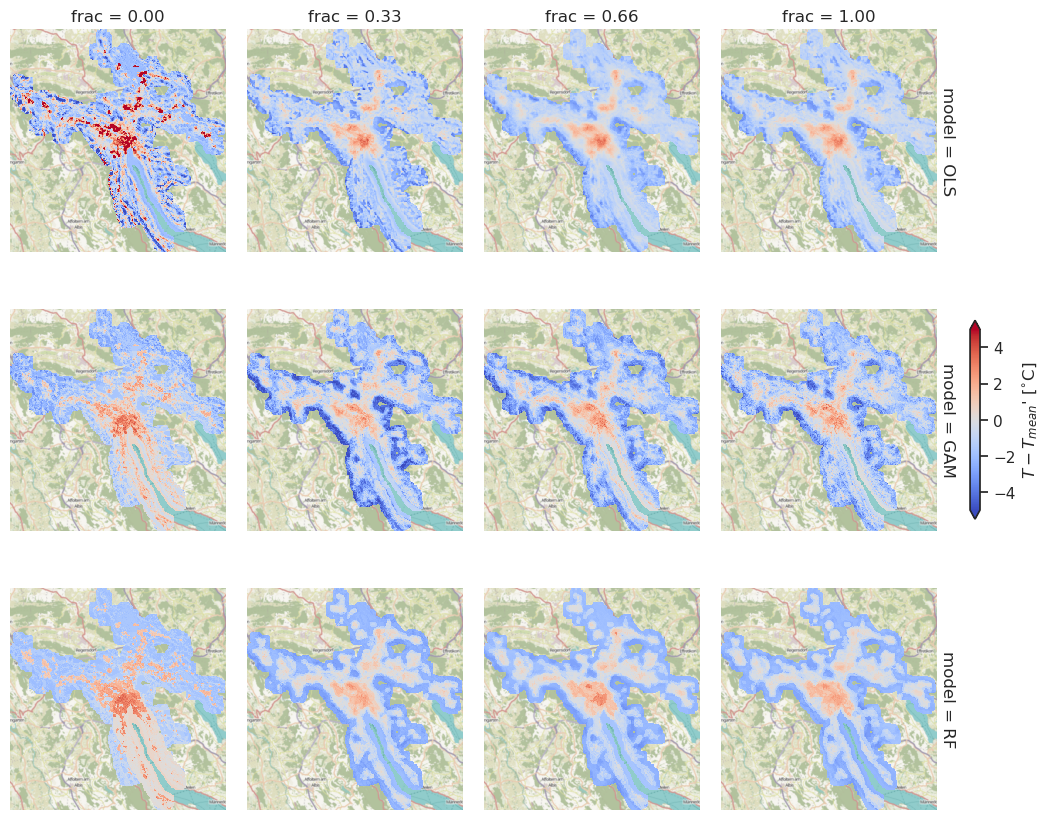

In [ ]:
pred_label = r"$T-T_{mean}$' [$^{\circ}$C]"


def predict_raster(pipe, grid_gdf, *, pred_label="pred"):
    X_pred = grid_gdf.drop(columns=["geometry", "source"], errors="ignore")
    preds = pipe.predict(X_pred)
    pred_gdf = gpd.GeoDataFrame(
        pd.Series(preds, index=grid_gdf.index, name=pred_label),
        geometry=grid_gdf["geometry"],
    )
    pred_gdf["x"] = pred_gdf.geometry.x
    pred_gdf["y"] = pred_gdf.geometry.y
    return (
        pred_gdf.reset_index(drop=True)
        .set_index(["y", "x"])
        .drop(columns="geometry")
        .to_xarray()[pred_label]
    )


pred_da = xr.concat(
    [
        xr.concat(
            [
                predict_raster(
                    frac_pipelines[frac][model_key],
                    grid_features_gdf,
                    pred_label=pred_label,
                )
                for model_key in MODEL_KEYS
            ],
            pd.Index(MODEL_KEYS, name="model"),
        )
        for frac in fracs
    ],
    pd.Index(fracs, name="frac"),
)

x_range = float(pred_da.x.max() - pred_da.x.min())
y_range = float(pred_da.y.max() - pred_da.y.min())

g = pred_da.plot(
    col="frac",
    row="model",
    vmin=-5,
    vmax=5,
    cmap="coolwarm",
    aspect=abs(x_range / y_range),
    cbar_kwargs={"shrink": 0.25, "pad": 0.03},
)

for ax in g.axs.flat:
    ax.set_aspect("equal")
    ax.set_axis_off()
    cx.add_basemap(ax, crs=grid_features_gdf.crs, attribution=False)

for ax, frac in zip(g.axs[0], fracs):
    ax.set_title(f"frac = {frac:.2f}")
for ax, model_key in zip(g.axs[:, -1], MODEL_KEYS):
    ax.set_ylabel(model_key)

g.fig.savefig(dst_maps_filepath, dpi=300, bbox_inches="tight")